#**Etapa 1 · Selección**

In [65]:
#Importar librerias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
#Seed 42
import numpy as np

SEED = 42
np.random.seed(SEED)

In [67]:
#Configuracion general
pd.set_option('display.max_columns', None)


In [68]:
# Cargar dataset
df = pd.read_csv(
    '/content/transacciones_bancarias.csv',
    parse_dates=['fecha_hora']
)

In [69]:
#Primera vista
print("Dimensiones del dataset:", df.shape)

display(df.head())

print("\nInformacion del dataset:")
df.info()

Dimensiones del dataset: (5000, 11)


,id_transaccion,fecha_hora,id_cliente,edad_cliente,antiguedad_cuenta_meses,tipo_transaccion,monto,canal,region,estado_transaccion,es_fraude
0,1,2024-08-29 17:11:00,845,59.0,134,Depósito,277.26,Teléfono,Alajuela,Completada,0
1,2,2024-07-11 23:18:00,1422,41.0,189,Retiro,21.38,Web,Alajuela,Completada,0
2,3,2024-05-01 13:13:00,41,28.0,8,Depósito,35.65,ATM,San José,Completada,0
3,4,2024-08-05 15:59:00,1475,56.0,121,Pago servicios,271.13,Web,Alajuela,Completada,0
4,5,2024-12-09 05:48:00,1462,18.0,110,Retiro,290.32,ATM,San José,Completada,0



Informacion del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id_transaccion           5000 non-null   int64         
 1   fecha_hora               5000 non-null   datetime64[ns]
 2   id_cliente               5000 non-null   int64         
 3   edad_cliente             4929 non-null   float64       
 4   antiguedad_cuenta_meses  5000 non-null   int64         
 5   tipo_transaccion         5000 non-null   object        
 6   monto                    5000 non-null   float64       
 7   canal                    4941 non-null   object        
 8   region                   4921 non-null   object        
 9   estado_transaccion       5000 non-null   object        
 10  es_fraude                5000 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(4), object(4)
memory usage: 4

In [70]:
#Tipos de variables
resumen_variables = pd.DataFrame({
    'Variable': df.columns,
    'Tipo_dato': df.dtypes.astype(str),
    'Valores_unicos': [df[col].nunique() for col in df.columns]
})

display(resumen_variables)

,Variable,Tipo_dato,Valores_unicos
id_transaccion,id_transaccion,int64,5000
fecha_hora,fecha_hora,datetime64[ns],4978
id_cliente,id_cliente,int64,1444
edad_cliente,edad_cliente,float64,64
antiguedad_cuenta_meses,antiguedad_cuenta_meses,int64,239
tipo_transaccion,tipo_transaccion,object,6
monto,monto,float64,4409
canal,canal,object,5
region,region,object,5
estado_transaccion,estado_transaccion,object,4


La lógica sería esta: id_transaccion tiene 5.000 valores únicos para 5.000 registros, así que funciona únicamente como identificador y no debería aportar un patrón generalizable de fraude. id_cliente tiene 1.444 valores únicos; aunque puede contener información indirecta del comportamiento del cliente, usar el número de identificación como predictor no tiene significado cuantitativo real, por lo que lo más razonable es excluirlo del modelo directo. En cambio, fecha_hora sí la conservamos porque más adelante podemos extraer características útiles como la hora del día o si la operación ocurrió de noche. Eso encaja además con el requisito posterior de crear variables derivadas.

In [71]:
#Tasa global de fraude
conteo_fraude = df['es_fraude'].value_counts()
porcentaje_fraude = df['es_fraude'].value_counts(normalize=True) * 100

print("Conteo:")
print(conteo_fraude)

print("\nPorcentaje:")
print(porcentaje_fraude)

tasa_fraude = df['es_fraude'].mean() * 100
print(f"\nTasa global de fraude: {tasa_fraude:.2f}%")

Conteo:
es_fraude
0    4891
1     109
Name: count, dtype: int64

Porcentaje:
es_fraude
0    97.82
1     2.18
Name: proportion, dtype: float64

Tasa global de fraude: 2.18%


###**Interpretacion de la Etapa 1:**

El conjunto de datos contiene 5.000 transacciones bancarias y 11 variables. Se identificaron variables numéricas, categóricas, temporales, identificadores y una variable objetivo binaria denominada `es_fraude`.

Las variables `id_transaccion` e `id_cliente` se consideran identificadores. `id_transaccion` presenta 5.000 valores únicos, por lo que únicamente permite distinguir registros y no representa una característica útil para explicar el fraude. Por su parte, `id_cliente` también corresponde a un identificador, por lo que no se utilizará directamente como predictor. La variable `fecha_hora` se conservará inicialmente, ya que permitirá generar posteriormente variables derivadas relacionadas con el momento en que ocurre cada transacción.

Las variables `edad_cliente`, `antiguedad_cuenta_meses` y `monto` se clasifican como numéricas, mientras que `tipo_transaccion`, `canal`, `region` y `estado_transaccion` corresponden a variables categóricas. Finalmente, `es_fraude` representa la variable objetivo del análisis.

La tasa global de fraude obtenida fue de 2.18%, correspondiente a 109 transacciones fraudulentas de un total de 5.000. El 97.82% restante corresponde a transacciones legítimas. Esto evidencia un importante desbalance de clases. Por esta razón, la evaluación posterior de los modelos no deberá basarse únicamente en la exactitud o accuracy, ya que un modelo podría obtener un valor elevado simplemente clasificando la mayoría de las transacciones como legítimas. Será necesario considerar métricas como precision, recall, F1 y AUC-ROC para evaluar adecuadamente la capacidad de detección de fraude.

#**Etapa 2 · Preprocesamiento**

In [72]:
#Diagnostico de valores nulos
nulos = pd.DataFrame({
    'Cantidad_nulos': df.isnull().sum(),
    'Porcentaje_nulos': (df.isnull().sum() / len(df) * 100).round(2)
})

display(nulos)

,Cantidad_nulos,Porcentaje_nulos
id_transaccion,0,0.00
fecha_hora,0,0.00
id_cliente,0,0.00
edad_cliente,71,1.42
antiguedad_cuenta_meses,0,0.00
tipo_transaccion,0,0.00
monto,0,0.00
canal,59,1.18
region,79,1.58
estado_transaccion,0,0.00


In [73]:
#Revision edad_cliente
print("Estadísticas de edad_cliente:")
print(df['edad_cliente'].describe())

print("\nMedia:", df['edad_cliente'].mean())
print("Mediana:", df['edad_cliente'].median())

Estadísticas de edad_cliente:
count    4929.000000
mean       39.724082
std        12.567357
min        18.000000
25%        31.000000
50%        40.000000
75%        48.000000
max        84.000000
Name: edad_cliente, dtype: float64

Media: 39.7240819638872
Mediana: 40.0


In [74]:
#Revision categoricas
print("Distribución de canal:")
print(df['canal'].value_counts(dropna=False))

print("\nDistribución de region:")
print(df['region'].value_counts(dropna=False))

Distribución de canal:
canal
App móvil    1738
Web          1490
ATM           709
Teléfono      524
Sucursal      480
NaN            59
Name: count, dtype: int64

Distribución de region:
region
San José    1947
Alajuela    1257
Cartago      722
Heredia      512
Otras        483
NaN           79
Name: count, dtype: int64




*   Para edad_cliente, la media es 39.72 y la mediana es 40, prácticamente iguales. Eso indica que no hay una asimetría fuerte en esta variable. Podemos usar la mediana, porque además es más robusta ante posibles valores extremos.Para canal, la categoría más frecuente es App móvil.
* Para region, la categoría más frecuente es San José.

Ahora bien, para las variables categóricas prefiero que usemos “Desconocido” en lugar de la moda. La razón es que imputar todos los faltantes como “App móvil” o “San José” introduciría información que realmente no conocemos y podría distorsionar la distribución original. Crear una categoría explícita conserva mejor la incertidumbre del dato faltante.

In [75]:
# Imputación de edad_cliente con la mediana
df['edad_cliente'] = df['edad_cliente'].fillna(df['edad_cliente'].median())

In [76]:
# Imputación de variables categóricas con una categoría explícita
df['canal'] = df['canal'].fillna('Desconocido')
df['region'] = df['region'].fillna('Desconocido')

In [77]:
# Verificar que no queden nulos
print(df[['edad_cliente', 'canal', 'region']].isnull().sum())

edad_cliente    0
canal           0
region          0
dtype: int64


Se identificaron valores faltantes en tres variables: `edad_cliente` con 71 registros (1.42%), `canal` con 59 registros (1.18%) y `region` con 79 registros (1.58%). Debido a que el porcentaje de valores faltantes fue bajo, se decidió conservar las observaciones y aplicar estrategias de imputación en lugar de eliminar registros.

En `edad_cliente`, la media fue de 39.72 años y la mediana de 40 años, valores prácticamente equivalentes. Se utilizó la mediana como método de imputación debido a su mayor robustez ante posibles valores extremos.

Para las variables categóricas `canal` y `region`, los valores faltantes fueron reemplazados por la categoría "Desconocido". Se prefirió esta estrategia sobre la imputación por moda para evitar asignar artificialmente los casos faltantes a las categorías más frecuentes y conservar explícitamente la ausencia de información como una característica del registro.

In [78]:
#Deteccion de duplicados
duplicados = df.duplicated().sum()
print("Cantidad de registros duplicados:", duplicados)

Cantidad de registros duplicados: 0


Se realizó una verificación de registros duplicados en el conjunto de datos y no se identificaron observaciones repetidas. Por lo tanto, no fue necesario eliminar registros en esta etapa y el dataset mantiene sus 5.000 transacciones originales.

In [79]:
#Deteccion de outliers: IQR
variables_numericas = [
    'edad_cliente',
    'antiguedad_cuenta_meses',
    'monto'
]

for variable in variables_numericas:
    Q1 = df[variable].quantile(0.25)
    Q3 = df[variable].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[variable] < limite_inferior) |
        (df[variable] > limite_superior)
    ]

    print(f"\nVariable: {variable}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Límite inferior: {limite_inferior:.2f}")
    print(f"Límite superior: {limite_superior:.2f}")
    print(f"Cantidad de outliers: {len(outliers)}")


Variable: edad_cliente
Q1: 31.00
Q3: 48.00
IQR: 17.00
Límite inferior: 5.50
Límite superior: 73.50
Cantidad de outliers: 18

Variable: antiguedad_cuenta_meses
Q1: 62.00
Q3: 182.00
IQR: 120.00
Límite inferior: -118.00
Límite superior: 362.00
Cantidad de outliers: 0

Variable: monto
Q1: 20.72
Q3: 164.39
IQR: 143.68
Límite inferior: -194.80
Límite superior: 379.91
Cantidad de outliers: 584


In [80]:
#Comparar fraude en outliers vs no outliers
Q1 = df['monto'].quantile(0.25)
Q3 = df['monto'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

df['outlier_monto'] = (
    (df['monto'] < limite_inferior) |
    (df['monto'] > limite_superior)
)

comparacion_outliers = df.groupby('outlier_monto')['es_fraude'].agg(
    cantidad='count',
    fraudes='sum',
    tasa_fraude='mean'
)

comparacion_outliers['tasa_fraude'] *= 100

display(comparacion_outliers)

,cantidad,fraudes,tasa_fraude
outlier_monto,,,
False,4416,28,0.634058
True,584,81,13.869863


El método IQR identificó 584 transacciones atípicas en la variable `monto`, utilizando un límite superior de 379.91. Al comparar la presencia de fraude entre transacciones atípicas y no atípicas, se observó una diferencia considerable.

Las transacciones que no fueron clasificadas como outliers presentaron una tasa de fraude de aproximadamente 0.63%, mientras que las transacciones identificadas como outliers alcanzaron una tasa de fraude de 13.87%. Esto evidencia que los montos extremos contienen información relevante para la identificación de operaciones fraudulentas.

Por esta razón, se decidió conservar los outliers de `monto` en el conjunto de datos. Eliminarlos podría reducir la capacidad de los modelos posteriores para reconocer patrones asociados al fraude.

In [81]:
#Outliers de edad y fraude
Q1_edad = df['edad_cliente'].quantile(0.25)
Q3_edad = df['edad_cliente'].quantile(0.75)
IQR_edad = Q3_edad - Q1_edad

limite_inf_edad = Q1_edad - 1.5 * IQR_edad
limite_sup_edad = Q3_edad + 1.5 * IQR_edad

df['outlier_edad'] = (
    (df['edad_cliente'] < limite_inf_edad) |
    (df['edad_cliente'] > limite_sup_edad)
)

comparacion_edad = df.groupby('outlier_edad')['es_fraude'].agg(
    cantidad='count',
    fraudes='sum',
    tasa_fraude='mean'
)

comparacion_edad['tasa_fraude'] *= 100

display(comparacion_edad)

,cantidad,fraudes,tasa_fraude
outlier_edad,,,
False,4982,109,2.187876
True,18,0,0.000000


El análisis mediante el método IQR mostró 18 valores atípicos en `edad_cliente`, ningún valor atípico en `antiguedad_cuenta_meses` y 584 valores atípicos en `monto`.

En el caso de `edad_cliente`, los 18 registros atípicos presentaron una tasa de fraude de 0%, mientras que el resto de las observaciones presentó una tasa de aproximadamente 2.19%. Dado que las edades observadas siguen siendo valores plausibles y no existen indicios de errores de registro, se decidió conservarlas.

Para `monto`, las transacciones identificadas como outliers presentaron una tasa de fraude de 13.87%, considerablemente superior al 0.63% observado entre las transacciones no atípicas. Este resultado demuestra que los montos extremos contienen información relevante para la detección de fraude.

En consecuencia, se decidió conservar todos los outliers identificados, ya que su eliminación podría implicar la pérdida de información útil para los modelos de detección de fraude.

In [82]:
#Transformación log1p() de monto
df['monto_log'] = np.log1p(df['monto'])

print(df[['monto', 'monto_log']].head())

print("\nAsimetría de monto original:")
print(df['monto'].skew())

print("\nAsimetría de monto_log:")
print(df['monto_log'].skew())

    monto  monto_log
0  277.26   5.628556
1   21.38   3.108168
2   35.65   3.601413
3  271.13   5.606280
4  290.32   5.674422

Asimetría de monto original:
8.659773526389609

Asimetría de monto_log:
1.6416544127851191


La variable `monto` presentó una asimetría positiva elevada, con un coeficiente de 8.66, producto de la presencia de transacciones con montos considerablemente superiores al resto de las observaciones. Para reducir esta asimetría sin eliminar los valores extremos, se aplicó la transformación `np.log1p()`, generando la variable `monto_log`. Posteriormente, la asimetría disminuyó a 1.64, evidenciando una distribución considerablemente menos sesgada. Esta transformación permite reducir el efecto de los montos extremadamente altos sobre los algoritmos posteriores, conservando al mismo tiempo la información que estos valores aportan para la detección de fraude.

#**Etapa 3 · Transformación**

In [83]:
# Extraer hora de la transacción
df['hora_dia'] = df['fecha_hora'].dt.hour

In [84]:
# Crear indicador de transacción nocturna
df['es_noche'] = (
    (df['hora_dia'] >= 0) &
    (df['hora_dia'] < 6)
).astype(int)

In [85]:
# Revisar las variables creadas
display(
    df[['fecha_hora', 'hora_dia', 'es_noche', 'monto', 'monto_log']].head(10)
)

,fecha_hora,hora_dia,es_noche,monto,monto_log
0,2024-08-29 17:11:00,17,0,277.26,5.628556
1,2024-07-11 23:18:00,23,0,21.38,3.108168
2,2024-05-01 13:13:00,13,0,35.65,3.601413
3,2024-08-05 15:59:00,15,0,271.13,5.606280
4,2024-12-09 05:48:00,5,1,290.32,5.674422
5,2024-12-15 22:18:00,22,0,9.60,2.360854
6,2024-08-04 19:01:00,19,0,11.46,2.522524
7,2024-07-20 08:52:00,8,0,178.65,5.191011
8,2024-04-17 07:40:00,7,0,38.61,3.679082
9,2024-02-12 00:42:00,0,1,43.26,3.790081


In [86]:
#Transacciones por hroario
print("Transacciones por horario:")
print(df['es_noche'].value_counts())

print("\nTasa de fraude según horario:")
print(
    df.groupby('es_noche')['es_fraude'].agg(
        cantidad='count',
        fraudes='sum',
        tasa_fraude='mean'
    )
)

Transacciones por horario:
es_noche
0    3752
1    1248
Name: count, dtype: int64

Tasa de fraude según horario:
          cantidad  fraudes  tasa_fraude
es_noche                                
0             3752       34     0.009062
1             1248       75     0.060096


Se generaron tres variables derivadas con potencial valor explicativo para la detección de fraude: `monto_log`, `hora_dia` y `es_noche`. La variable `monto_log` corresponde a la transformación logarítmica del monto original y permite reducir la asimetría de esta variable. A partir de `fecha_hora` se extrajo `hora_dia`, que representa la hora en que ocurrió cada transacción. También se creó `es_noche`, una variable binaria que identifica las operaciones realizadas entre las 00:00 y las 05:59. El análisis mostró que las transacciones nocturnas presentan una tasa de fraude aproximada de 6.01%, mientras que las transacciones realizadas fuera de ese horario presentan una tasa cercana al 0.91%. Esta diferencia sugiere que el horario de la transacción puede aportar información útil para distinguir operaciones legítimas de fraudulenta

In [87]:
#Correlacion
variables_correlacion = [
    'edad_cliente',
    'antiguedad_cuenta_meses',
    'monto',
    'monto_log',
    'hora_dia',
    'es_noche',
    'es_fraude'
]

matriz_correlacion = df[variables_correlacion].corr()

display(matriz_correlacion.round(3))

,edad_cliente,antiguedad_cuenta_meses,monto,monto_log,hora_dia,es_noche,es_fraude
edad_cliente,1.000,0.012,-0.018,-0.022,0.001,-0.015,0.011
antiguedad_cuenta_meses,0.012,1.000,0.015,0.007,-0.020,0.025,0.048
monto,-0.018,0.015,1.000,0.591,-0.028,0.032,0.322
monto_log,-0.022,0.007,0.591,1.000,-0.019,0.018,0.314
hora_dia,0.001,-0.020,-0.028,-0.019,1.000,-0.749,-0.099
es_noche,-0.015,0.025,0.032,0.018,-0.749,1.000,0.151
es_fraude,0.011,0.048,0.322,0.314,-0.099,0.151,1.000


In [88]:
#Buscar pares con correlación absoluta mayor a 0.8
pares_altos = []

for i in range(len(matriz_correlacion.columns)):
    for j in range(i + 1, len(matriz_correlacion.columns)):
        var1 = matriz_correlacion.columns[i]
        var2 = matriz_correlacion.columns[j]
        r = matriz_correlacion.iloc[i, j]

        if abs(r) > 0.8:
            pares_altos.append((var1, var2, r))

print("Pares con |r| > 0.8:")
for par in pares_altos:
    print(par)

Pares con |r| > 0.8:


La matriz de correlación no identificó pares de variables con un coeficiente absoluto superior a 0.8, por lo que no se evidencia un problema severo de multicolinealidad según el criterio establecido. La relación más elevada se observó entre `hora_dia` y `es_noche`, con una correlación de -0.749. Esta relación es esperable debido a que `es_noche` fue construida directamente a partir de `hora_dia`. Sin embargo, al no superar el umbral de |r| > 0.8, ambas variables pueden mantenerse inicialmente para las etapas posteriores. Asimismo, `monto` y `monto_log` presentaron una correlación moderada de 0.591. Respecto a la variable objetivo `es_fraude`, las asociaciones lineales más altas se observaron con `monto` (0.322), `monto_log` (0.314) y `es_noche` (0.151). Estos resultados sugieren que el monto y el horario de las transacciones podrían aportar información relevante para la detección de fraude.

In [89]:
#Separacion de variables
X = df[[
    'edad_cliente',
    'antiguedad_cuenta_meses',
    'tipo_transaccion',
    'monto',
    'canal',
    'region',
    'estado_transaccion',
    'monto_log',
    'hora_dia',
    'es_noche'
]]

y = df['es_fraude']

print("Columnas predictoras:")
print(X.columns.tolist())

print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Columnas predictoras:
['edad_cliente', 'antiguedad_cuenta_meses', 'tipo_transaccion', 'monto', 'canal', 'region', 'estado_transaccion', 'monto_log', 'hora_dia', 'es_noche']

Dimensiones de X: (5000, 10)
Dimensiones de y: (5000,)


In [90]:
#Datos de entrenamiento y prueba
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Dimensiones de entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nDimensiones de prueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTasa de fraude en entrenamiento:")
print(y_train.mean() * 100)

print("\nTasa de fraude en prueba:")
print(y_test.mean() * 100)

Dimensiones de entrenamiento:
X_train: (4000, 10)
y_train: (4000,)

Dimensiones de prueba:
X_test: (1000, 10)
y_test: (1000,)

Tasa de fraude en entrenamiento:
2.175

Tasa de fraude en prueba:
2.1999999999999997


In [91]:
#Definicion de columnas
columnas_numericas = [
    'edad_cliente',
    'antiguedad_cuenta_meses',
    'monto',
    'monto_log',
    'hora_dia',
    'es_noche'
]

columnas_categoricas = [
    'tipo_transaccion',
    'canal',
    'region',
    'estado_transaccion'
]

print("Variables numéricas:")
print(columnas_numericas)

print("\nVariables categóricas:")
print(columnas_categoricas)

Variables numéricas:
['edad_cliente', 'antiguedad_cuenta_meses', 'monto', 'monto_log', 'hora_dia', 'es_noche']

Variables categóricas:
['tipo_transaccion', 'canal', 'region', 'estado_transaccion']


In [92]:
#Crear el preprocesador
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocesador = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            columnas_numericas
        ),
        (
            'cat',
            OneHotEncoder(
                drop='first',
                handle_unknown='ignore'
            ),
            columnas_categoricas
        )
    ]
)

print(preprocesador)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['edad_cliente', 'antiguedad_cuenta_meses',
                                  'monto', 'monto_log', 'hora_dia',
                                  'es_noche']),
                                ('cat',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['tipo_transaccion', 'canal', 'region',
                                  'estado_transaccion'])])


In [93]:
#Ajustar y transformar train y test
X_train_transformado = preprocesador.fit_transform(X_train)
X_test_transformado = preprocesador.transform(X_test)

print("Dimensiones de X_train transformado:", X_train_transformado.shape)
print("Dimensiones de X_test transformado:", X_test_transformado.shape)

Dimensiones de X_train transformado: (4000, 24)
Dimensiones de X_test transformado: (1000, 24)


In [94]:
#Creacion del pipeline
from sklearn.pipeline import Pipeline

pipeline_transformacion = Pipeline(
    steps=[
        ('preprocesamiento', preprocesador)
    ]
)

print(pipeline_transformacion)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['edad_cliente',
                                                   'antiguedad_cuenta_meses',
                                                   'monto', 'monto_log',
                                                   'hora_dia', 'es_noche']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['tipo_transaccion', 'canal',
                                                   'region',
                                                   'estado_transaccion'])]))])


#**Etapa 4 · Minería de datos**

In [95]:
#kmeans
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inercias = []
siluetas = []

valores_k = range(2, 11)

for k in valores_k:
    modelo_kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo_kmeans.fit_predict(X_train_transformado)

    inercias.append(modelo_kmeans.inertia_)
    siluetas.append(
        silhouette_score(X_train_transformado, etiquetas)
    )

resultados_kmeans = pd.DataFrame({
    'k': list(valores_k),
    'inercia': inercias,
    'silueta': siluetas
})

display(resultados_kmeans)

,k,inercia,silueta
0,2,25797.321282,0.254665
1,3,21083.337682,0.262756
2,4,18842.706715,0.172085
3,5,17569.303862,0.155169
4,6,16850.903027,0.130490
5,7,16175.730200,0.114016
6,8,15642.901675,0.112777
7,9,15184.015943,0.108995
8,10,14737.639639,0.107760


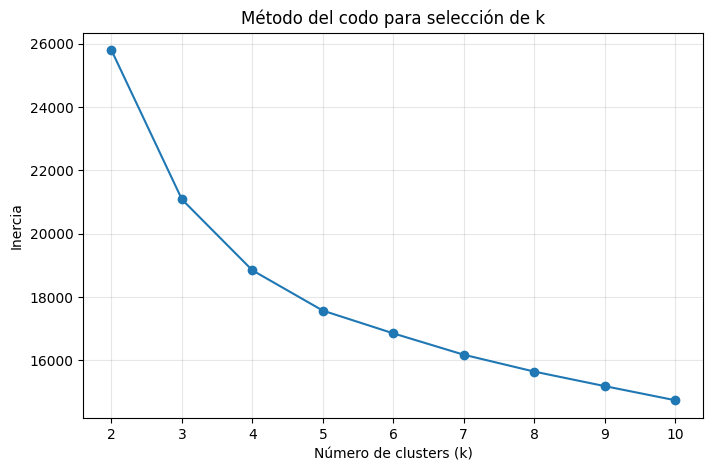

In [96]:
#Grafico de inercia
plt.figure(figsize=(8, 5))

plt.plot(
    resultados_kmeans['k'],
    resultados_kmeans['inercia'],
    marker='o'
)

plt.title('Método del codo para selección de k')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia')
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)

plt.show()

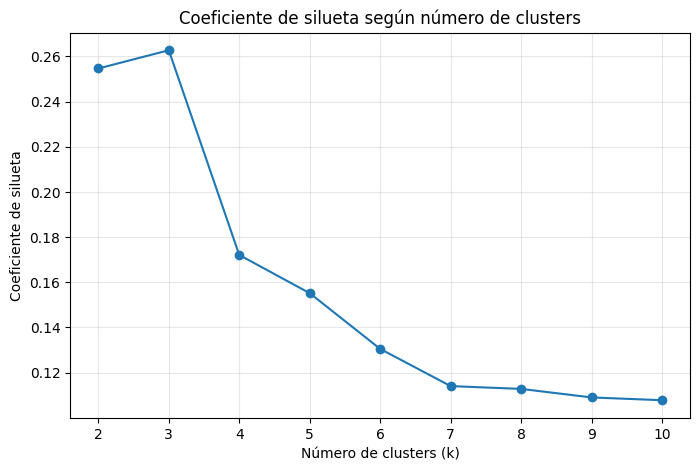

In [97]:
#Silueta
plt.figure(figsize=(8, 5))

plt.plot(
    resultados_kmeans['k'],
    resultados_kmeans['silueta'],
    marker='o'
)

plt.title('Coeficiente de silueta según número de clusters')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Coeficiente de silueta')
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)

plt.show()

Para seleccionar el número óptimo de clusters se evaluaron valores de k entre 2 y 10 mediante el método del codo y el coeficiente de silueta.

El gráfico de inercia muestra una reducción pronunciada entre k=2 y k=3, seguida por mejoras progresivamente menores conforme aumenta el número de clusters. Este comportamiento sugiere un punto de inflexión alrededor de k=3.

El análisis de silueta refuerza esta decisión, ya que el valor máximo se obtuvo con k=3, con un coeficiente aproximado de 0.263. A partir de este punto, el coeficiente disminuye de forma considerable.

Por lo tanto, se seleccionó k=3 como el número óptimo de clusters para el modelo K-Means, al ofrecer el mejor equilibrio entre compactación interna y separación entre grupos.

In [98]:
#Clusters
kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters_kmeans = kmeans_final.fit_predict(X_train_transformado)

conteo_clusters = pd.Series(clusters_kmeans).value_counts().sort_index()

print("Cantidad de transacciones por cluster:")
print(conteo_clusters)

Cantidad de transacciones por cluster:
0     978
1    2952
2      70
Name: count, dtype: int64


In [99]:
resultado_clusters = pd.DataFrame({
    'cluster': clusters_kmeans,
    'es_fraude': y_train.reset_index(drop=True)
})

comparacion_clusters = resultado_clusters.groupby('cluster')['es_fraude'].agg(
    cantidad='count',
    fraudes='sum',
    tasa_fraude='mean'
)

comparacion_clusters['tasa_fraude'] *= 100

display(comparacion_clusters)

,cantidad,fraudes,tasa_fraude
cluster,,,
0,978,34,3.476483
1,2952,27,0.914634
2,70,26,37.142857


El modelo K-Means con k=3 generó tres grupos con tamaños claramente diferentes. El cluster 0 agrupó 978 transacciones, el cluster 1 concentró 2.952 y el cluster 2 únicamente 70 transacciones.

Al comparar posteriormente estos grupos con la variable real de fraude, se observó que el cluster 1 presentó una tasa de fraude de aproximadamente 0.91%, mientras que el cluster 0 alcanzó 3.48%. El resultado más relevante se encontró en el cluster 2, donde 26 de las 70 transacciones fueron fraudulentas, equivalente a una tasa de fraude de 37.14%.

Este hallazgo indica que K-Means logró identificar un grupo pequeño de transacciones con características atípicas y una concentración de fraude considerablemente superior al promedio general del dataset. Aunque el clustering no utiliza la variable `es_fraude` durante su entrenamiento, el análisis posterior muestra que los grupos obtenidos pueden ser útiles para identificar perfiles de mayor riesgo.

In [100]:
#DBSCAN
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=1.5,
    min_samples=10
)

clusters_dbscan = dbscan.fit_predict(X_train_transformado)

print("Etiquetas encontradas:")
print(pd.Series(clusters_dbscan).value_counts().sort_index())

Etiquetas encontradas:
-1     894
 0    2420
 1     686
Name: count, dtype: int64


In [101]:
#Comparar anomalías DBSCAN con fraude
resultado_dbscan = pd.DataFrame({
    'cluster_dbscan': clusters_dbscan,
    'es_fraude': y_train.reset_index(drop=True)
})

# Nos quedamos únicamente con las anomalías (-1)
anomalias_dbscan = resultado_dbscan[
    resultado_dbscan['cluster_dbscan'] == -1
]

cantidad_anomalias = len(anomalias_dbscan)
fraudes_en_anomalias = anomalias_dbscan['es_fraude'].sum()
porcentaje_fraude_anomalias = (
    anomalias_dbscan['es_fraude'].mean() * 100
)

print("Cantidad de anomalías detectadas:", cantidad_anomalias)
print("Fraudes reales entre las anomalías:", fraudes_en_anomalias)
print(f"Porcentaje de anomalías que son fraude: {porcentaje_fraude_anomalias:.2f}%")

Cantidad de anomalías detectadas: 894
Fraudes reales entre las anomalías: 51
Porcentaje de anomalías que son fraude: 5.70%


El algoritmo DBSCAN, utilizando `eps=1.5` y `min_samples=10`, identificó 894 transacciones como anomalías, representadas por la etiqueta `-1`.

De estas anomalías, 51 correspondieron a fraudes reales, lo que representa una tasa de fraude de aproximadamente 5.70%. Este porcentaje es superior a la tasa global de fraude del conjunto de datos, que fue de 2.18%, lo que indica que DBSCAN logró concentrar una mayor proporción de operaciones fraudulentas dentro del grupo de observaciones anómalas.

Sin embargo, la mayoría de las anomalías detectadas correspondieron a transacciones legítimas, por lo que DBSCAN no debe interpretarse como un clasificador definitivo de fraude, sino como una herramienta complementaria para identificar operaciones atípicas que podrían requerir revisión adicional.

In [102]:
#PCA
from sklearn.decomposition import PCA

# PCA con 2 componentes
pca_2 = PCA(n_components=2)
X_train_pca_2 = pca_2.fit_transform(X_train_transformado)

print("PCA con 2 componentes:")
print("Varianza explicada por componente:", pca_2.explained_variance_ratio_)
print("Varianza explicada acumulada:", pca_2.explained_variance_ratio_.sum())

# PCA con 3 componentes
pca_3 = PCA(n_components=3)
X_train_pca_3 = pca_3.fit_transform(X_train_transformado)

print("\nPCA con 3 componentes:")
print("Varianza explicada por componente:", pca_3.explained_variance_ratio_)
print("Varianza explicada acumulada:", pca_3.explained_variance_ratio_.sum())

PCA con 2 componentes:
Varianza explicada por componente: [0.22024696 0.1965458 ]
Varianza explicada acumulada: 0.41679276293938833

PCA con 3 componentes:
Varianza explicada por componente: [0.22024696 0.1965458  0.12611977]
Varianza explicada acumulada: 0.5429125336768965


Se aplicó Análisis de Componentes Principales (PCA) sobre las variables transformadas con el objetivo de reducir la dimensionalidad y facilitar la visualización de los patrones existentes en los datos.

Con dos componentes principales se explicó aproximadamente el 41.68% de la varianza total. Al incorporar un tercer componente, la varianza explicada acumulada aumentó a aproximadamente 54.29%.

Estos resultados indican que una representación en dos dimensiones no conserva toda la información original, pero sí permite visualizar una proporción relevante de la estructura de los datos. La representación con tres componentes retiene una mayor cantidad de información, aunque resulta menos directa para visualización gráfica en dos dimensiones.

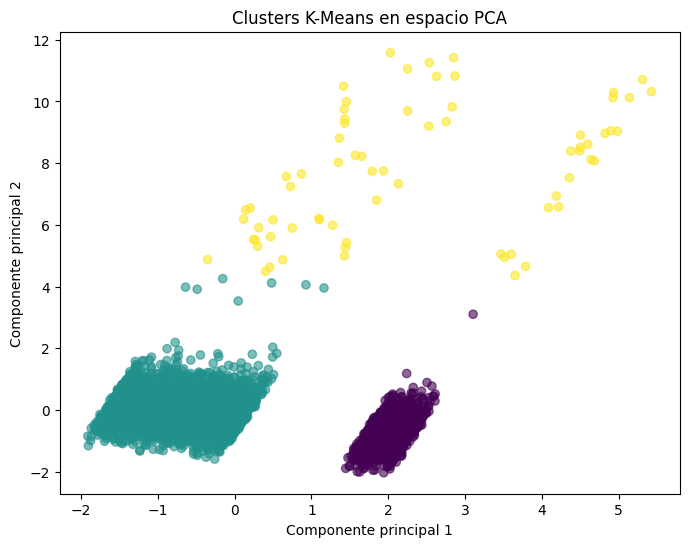

In [103]:
#Visualizar clusters en espacio PCA
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca_2[:, 0],
    X_train_pca_2[:, 1],
    c=clusters_kmeans,
    alpha=0.6
)

plt.title('Clusters K-Means en espacio PCA')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')

plt.show()

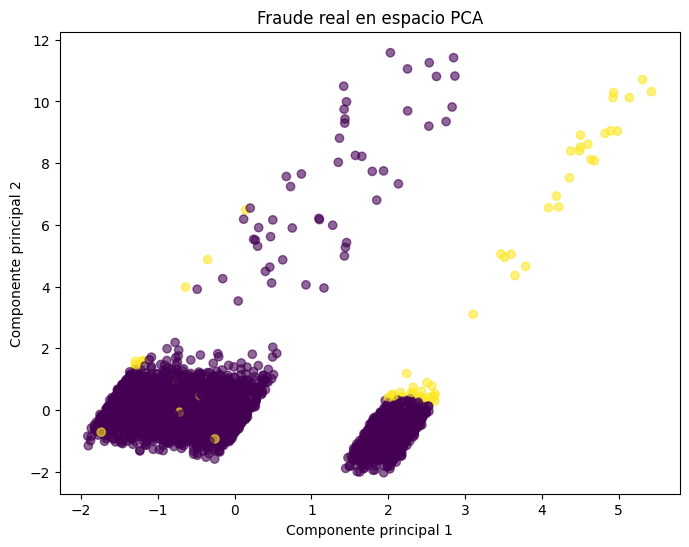

In [104]:
#Segun el fraude real

plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca_2[:, 0],
    X_train_pca_2[:, 1],
    c=y_train.reset_index(drop=True),
    alpha=0.6
)

plt.title('Fraude real en espacio PCA')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')

plt.show()

La representación de los datos mediante las dos primeras componentes principales permite observar una separación visible entre los tres clusters obtenidos con K-Means. En particular, uno de los grupos aparece claramente apartado de las zonas de mayor concentración de transacciones.

Al colorear las observaciones según la variable real `es_fraude`, se observa una mayor presencia de casos fraudulentos en algunas de las regiones más separadas del espacio PCA. Este comportamiento es consistente con el análisis previo de K-Means, donde el cluster 2 presentó una tasa de fraude de 37.14%, considerablemente superior a la observada en los demás grupos.

La visualización sugiere que existen perfiles transaccionales diferenciados asociados a un mayor riesgo de fraude. Sin embargo, debe considerarse que las dos primeras componentes principales explican aproximadamente el 41.68% de la varianza total, por lo que el gráfico representa una simplificación de la estructura original de los datos.

In [105]:
class_weight='balanced'

In [106]:
#Regresion logistica
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

pipeline_logistica = Pipeline(
    steps=[
        ('preprocesamiento', preprocesador),
        ('modelo', LogisticRegression(
            class_weight='balanced',
            random_state=42,
            max_iter=1000
        ))
    ]
)

pipeline_logistica.fit(X_train, y_train)

print("Modelo de Regresión Logística entrenado correctamente.")

Modelo de Regresión Logística entrenado correctamente.


In [107]:
#Metricas
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

#Predicciones de clase
y_pred_logistica = pipeline_logistica.predict(X_test)

#Probabilidad estimada de fraude
y_prob_logistica = pipeline_logistica.predict_proba(X_test)[:, 1]

#Metricas
accuracy_logistica = accuracy_score(y_test, y_pred_logistica)
precision_logistica = precision_score(y_test, y_pred_logistica)
recall_logistica = recall_score(y_test, y_pred_logistica)
f1_logistica = f1_score(y_test, y_pred_logistica)
auc_logistica = roc_auc_score(y_test, y_prob_logistica)

print(f"Accuracy:  {accuracy_logistica:.4f}")
print(f"Precision: {precision_logistica:.4f}")
print(f"Recall:    {recall_logistica:.4f}")
print(f"F1-score:  {f1_logistica:.4f}")
print(f"AUC-ROC:   {auc_logistica:.4f}")

Accuracy:  0.8430
Precision: 0.1053
Recall:    0.8182
F1-score:  0.1865
AUC-ROC:   0.9012


La Regresión Logística obtuvo una exactitud de 84.30%, una precisión de 10.53%, un recall de 81.82%, un F1-score de 18.65% y un AUC-ROC de 90.12%.

El resultado más relevante es el recall, ya que el modelo logró identificar aproximadamente el 81.82% de los fraudes reales presentes en el conjunto de prueba. Esto es favorable en un contexto de prevención de fraude, donde los falsos negativos pueden representar pérdidas financieras importantes.

Sin embargo, la precisión fue baja, de 10.53%, lo que indica que una proporción considerable de las transacciones clasificadas como fraudulentas correspondieron en realidad a operaciones legítimas. Por lo tanto, el modelo presenta un trade-off entre una alta capacidad de detección y una elevada cantidad de falsas alarmas.

El AUC-ROC de 0.9012 indica una buena capacidad general de discriminación entre transacciones legítimas y fraudulentas.

In [108]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

pipeline_rf = Pipeline(
    steps=[
        ('preprocesamiento', preprocesador),
        ('modelo', RandomForestClassifier(
            n_estimators=200,
            class_weight='balanced',
            random_state=42
        ))
    ]
)

pipeline_rf.fit(X_train, y_train)

print("Modelo Random Forest entrenado correctamente.")

Modelo Random Forest entrenado correctamente.


In [109]:
#Predicciones de clase
y_pred_rf = pipeline_rf.predict(X_test)

#Probabilidad estimada de fraude
y_prob_rf = pipeline_rf.predict_proba(X_test)[:, 1]

#Metricas
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-score:  {f1_rf:.4f}")
print(f"AUC-ROC:   {auc_rf:.4f}")

Accuracy:  0.9930
Precision: 1.0000
Recall:    0.6818
F1-score:  0.8108
AUC-ROC:   0.8808


La Regresión Logística y el Random Forest mostraron comportamientos distintos frente al problema de detección de fraude.

La Regresión Logística alcanzó un recall de 81.82%, superior al 68.18% obtenido por Random Forest, por lo que logró identificar una mayor proporción de los fraudes reales. Sin embargo, su precisión fue de solo 10.53%, lo que implica una cantidad considerable de falsas alarmas.

Random Forest presentó una precisión de 100%, un accuracy de 99.30% y un F1-score de 81.08%. Esto indica que todas las transacciones que clasificó como fraudulentas fueron efectivamente fraude. No obstante, su menor recall evidencia que dejó sin detectar una mayor proporción de fraudes reales.

La elección entre ambos modelos depende del costo asociado a los errores. En un contexto donde los falsos negativos representan pérdidas financieras significativas, la Regresión Logística ofrece una ventaja al detectar una mayor proporción de fraudes. En cambio, Random Forest reduce considerablemente las falsas alarmas y presenta un mejor equilibrio global entre precisión y recall.

In [110]:
from sklearn.metrics import confusion_matrix

# Matriz de confusión - Regresión Logística
cm_logistica = confusion_matrix(y_test, y_pred_logistica)

print("Matriz de confusión - Regresión Logística")
print(cm_logistica)

# Matriz de confusión - Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("\nMatriz de confusión - Random Forest")
print(cm_rf)

Matriz de confusión - Regresión Logística
[[825 153]
 [  4  18]]

Matriz de confusión - Random Forest
[[978   0]
 [  7  15]]


La matriz de confusión permitió analizar con mayor detalle los errores cometidos por cada modelo.

La Regresión Logística clasificó correctamente 825 transacciones legítimas y detectó 18 de los 22 fraudes reales presentes en el conjunto de prueba. Sin embargo, generó 153 falsos positivos y dejó pasar 4 transacciones fraudulentas. Este comportamiento explica su elevado recall de 81.82% y su baja precisión de 10.53%.

Random Forest clasificó correctamente las 978 transacciones legítimas, sin generar falsos positivos, y detectó 15 de los 22 fraudes reales. No obstante, dejó pasar 7 operaciones fraudulentas. Esto explica su precisión de 100% y su recall inferior, de 68.18%.

Desde una perspectiva de prevención de fraude, los falsos negativos resultan especialmente relevantes debido a que representan operaciones fraudulentas que podrían ser autorizadas como legítimas. Si el costo financiero de un fraude no detectado supera el costo operativo de revisar falsas alarmas, la Regresión Logística presenta una ventaja al reducir los falsos negativos de 7 a 4.

In [111]:
#Tabla final de metrics
comparacion_modelos = pd.DataFrame({
    'Modelo': ['Regresión Logística', 'Random Forest'],
    'Accuracy': [accuracy_logistica, accuracy_rf],
    'Precision': [precision_logistica, precision_rf],
    'Recall': [recall_logistica, recall_rf],
    'F1': [f1_logistica, f1_rf],
    'AUC_ROC': [auc_logistica, auc_rf]
})

display(comparacion_modelos.round(4))

,Modelo,Accuracy,Precision,Recall,F1,AUC_ROC
0,Regresión Logística,0.843,0.1053,0.8182,0.1865,0.9012
1,Random Forest,0.993,1.0000,0.6818,0.8108,0.8808


#**Etapa 5 · Interpretación y visualización**

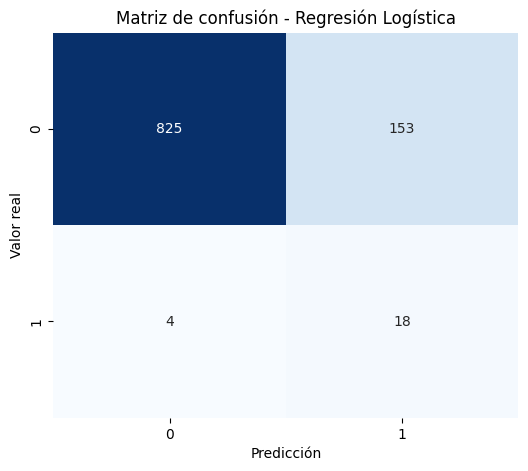

In [112]:
#Regresion logistica
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_logistica,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False
)

plt.title('Matriz de confusión - Regresión Logística')
plt.xlabel('Predicción')
plt.ylabel('Valor real')

plt.show()

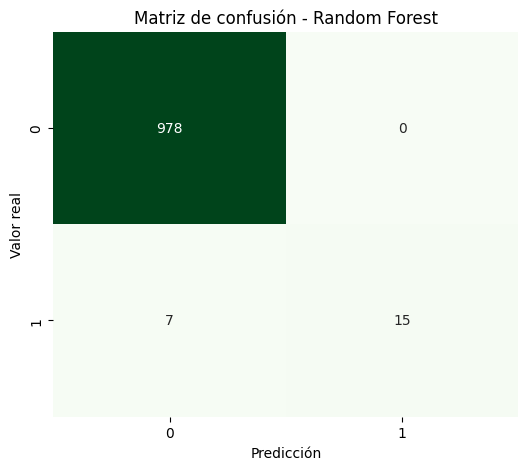

In [113]:
#Random Forest
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    cbar=False
)

plt.title('Matriz de confusión - Random Forest')
plt.xlabel('Predicción')
plt.ylabel('Valor real')

plt.show()

Las matrices de confusión evidencian diferencias importantes entre ambos modelos. La Regresión Logística logró identificar 18 de los 22 fraudes reales presentes en el conjunto de prueba y dejó sin detectar únicamente 4. Sin embargo, clasificó erróneamente 153 transacciones legítimas como fraudulentas.

Random Forest, por su parte, clasificó correctamente las 978 transacciones legítimas y no generó falsos positivos. No obstante, detectó 15 de los 22 fraudes reales y dejó pasar 7 operaciones fraudulentas.

Estos resultados reflejan un trade-off entre sensibilidad y precisión. La Regresión Logística prioriza la detección de fraude, mientras que Random Forest reduce considerablemente las falsas alarmas.

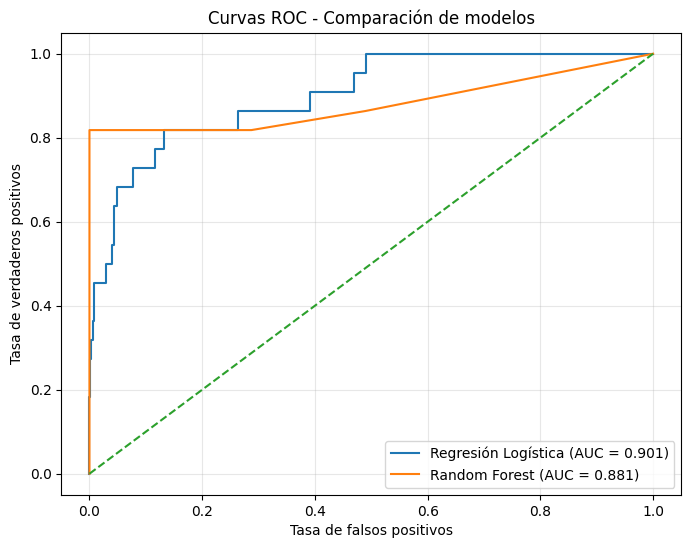

In [114]:
#Curvas ROC
from sklearn.metrics import roc_curve

#Curva ROC - Regresión Logística
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_logistica)

#Curva ROC - Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f'Regresión Logística (AUC = {auc_logistica:.3f})'
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f'Random Forest (AUC = {auc_rf:.3f})'
)

#Línea de referencia
plt.plot([0, 1], [0, 1], linestyle='--')

plt.title('Curvas ROC - Comparación de modelos')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Las curvas ROC muestran que ambos modelos presentan una capacidad de discriminación superior a la clasificación aleatoria, representada por la línea diagonal de referencia.

La Regresión Logística obtuvo un AUC-ROC de 0.901, ligeramente superior al 0.881 alcanzado por Random Forest. Esto indica que, considerando distintos posibles umbrales de clasificación, la Regresión Logística presenta una mayor capacidad global para diferenciar transacciones fraudulentas de legítimas.

Aunque Random Forest obtuvo mejores resultados en accuracy, precision y F1-score, la Regresión Logística mostró un mejor desempeño en recall y AUC-ROC. Por lo tanto, ambos modelos presentan ventajas distintas y su selección debe considerar el costo asociado a los diferentes tipos de error.

In [115]:
# Obtener nombres de las variables después del preprocesamiento
nombres_variables = (
    pipeline_rf
    .named_steps['preprocesamiento']
    .get_feature_names_out()
)

# Obtener importancia de variables
importancias = (
    pipeline_rf
    .named_steps['modelo']
    .feature_importances_
)

importancia_df = pd.DataFrame({
    'variable': nombres_variables,
    'importancia': importancias
})

# Ordenar de mayor a menor
importancia_df = importancia_df.sort_values(
    'importancia',
    ascending=False
)

display(importancia_df.head(10))

,variable,importancia
2,num__monto,0.291749
3,num__monto_log,0.223961
4,num__hora_dia,0.125909
1,num__antiguedad_cuenta_meses,0.097484
0,num__edad_cliente,0.066351
5,num__es_noche,0.046579
16,cat__region_Cartago,0.014728
15,cat__canal_Web,0.014417
11,cat__canal_App móvil,0.013413
20,cat__region_San José,0.012704


El análisis de importancia de variables del modelo Random Forest muestra que `monto` es la característica con mayor influencia en las predicciones, con una importancia aproximada de 0.292, seguida por `monto_log` con 0.224.

La tercera variable más relevante fue `hora_dia`, con una importancia cercana a 0.126. También se observó aporte de `antiguedad_cuenta_meses`, `edad_cliente` y `es_noche`.

Estos resultados son consistentes con los hallazgos obtenidos durante el análisis exploratorio. En particular, los montos atípicos presentaron una tasa de fraude considerablemente superior a las transacciones normales, mientras que las operaciones realizadas durante horario nocturno también mostraron una mayor incidencia de fraude.

Las variables categóricas relacionadas con región y canal presentan una importancia menor, aunque algunas categorías específicas, como Cartago, Web, App móvil y San José, contribuyen parcialmente a las decisiones del modelo.

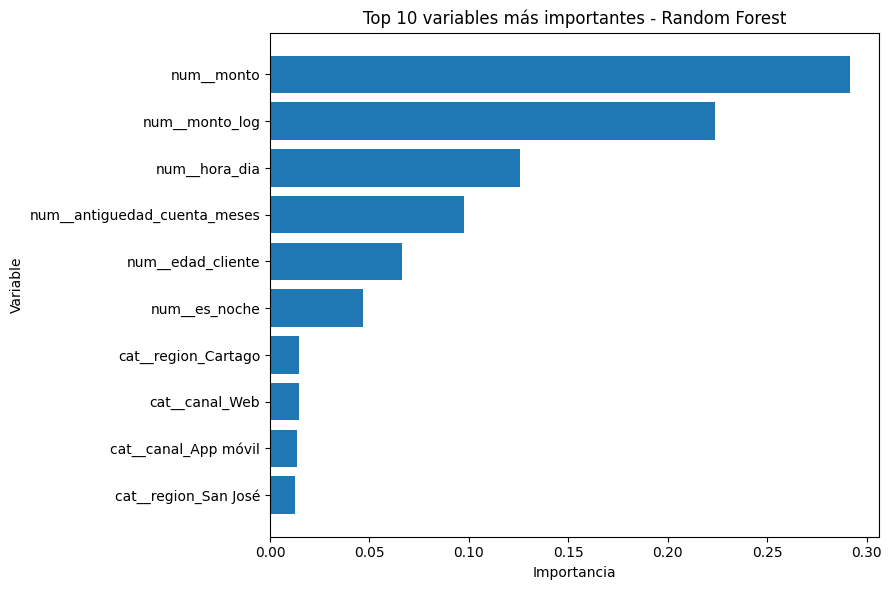

In [116]:
#Top 10 variables más importantes
top10_importancia = importancia_df.head(10).sort_values(
    'importancia',
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top10_importancia['variable'],
    top10_importancia['importancia']
)

plt.title('Top 10 variables más importantes - Random Forest')
plt.xlabel('Importancia')
plt.ylabel('Variable')

plt.tight_layout()
plt.show()

In [117]:
#Resumen
resumen_hallazgos = pd.DataFrame({
    'Hallazgo': [
        'Tasa global de fraude',
        'Fraude en outliers de monto',
        'Fraude en transacciones nocturnas',
        'Fraude en cluster K-Means de mayor riesgo',
        'Fraude entre anomalías DBSCAN',
        'Recall Regresión Logística',
        'Recall Random Forest'
    ],
    'Resultado': [
        '2.18%',
        '13.87%',
        '6.01%',
        '37.14%',
        '5.70%',
        '81.82%',
        '68.18%'
    ]
})

display(resumen_hallazgos)

,Hallazgo,Resultado
0,Tasa global de fraude,2.18%
1,Fraude en outliers de monto,13.87%
2,Fraude en transacciones nocturnas,6.01%
3,Fraude en cluster K-Means de mayor riesgo,37.14%
4,Fraude entre anomalías DBSCAN,5.70%
5,Recall Regresión Logística,81.82%
6,Recall Random Forest,68.18%


La historia general del proyecto ya se ve bastante clara: el fraude es poco frecuente en términos globales (2.18%), pero se concentra mucho más en ciertos patrones. Los montos atípicos presentan 13.87% de fraude, las transacciones nocturnas 6.01%, y el cluster de mayor riesgo identificado por K-Means alcanza 37.14%. DBSCAN también concentra fraude por encima del promedio, aunque de forma menos marcada (5.70%).

En los modelos supervisados aparece el trade-off central: la Regresión Logística detecta más fraudes (recall = 81.82%) pero genera muchas falsas alarmas, mientras que Random Forest es mucho más preciso (precision = 100%) pero detecta una proporción menor de fraudes (recall = 68.18%). Esto responde directamente a la pregunta central del proyecto: los patrones de monto y horario permiten distinguir perfiles de mayor riesgo, pero operacionalizarlos requiere equilibrar detección de fraude y fricción para clientes legítimos.

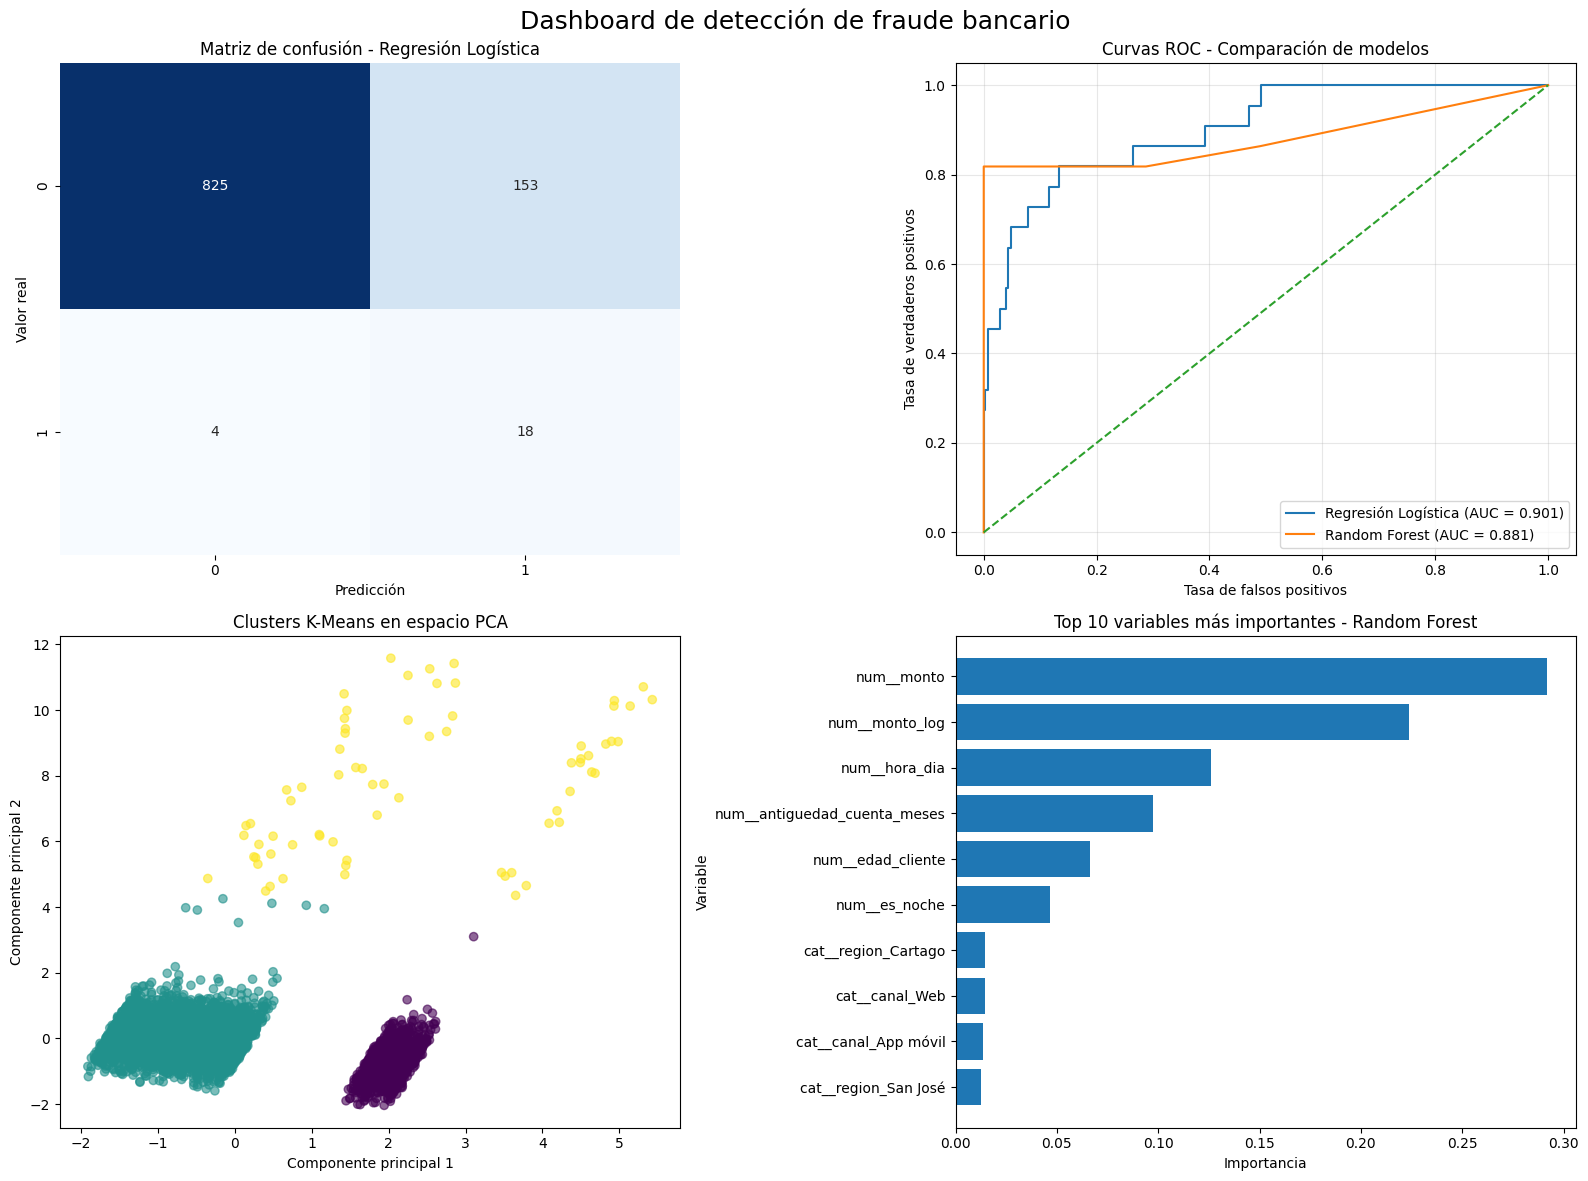

In [118]:
#Dashboard final
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Matriz de confusión - Regresión Logística
sns.heatmap(
    cm_logistica,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title('Matriz de confusión - Regresión Logística')
axes[0, 0].set_xlabel('Predicción')
axes[0, 0].set_ylabel('Valor real')


# 2. Curvas ROC comparativas
axes[0, 1].plot(
    fpr_log,
    tpr_log,
    label=f'Regresión Logística (AUC = {auc_logistica:.3f})'
)

axes[0, 1].plot(
    fpr_rf,
    tpr_rf,
    label=f'Random Forest (AUC = {auc_rf:.3f})'
)

axes[0, 1].plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

axes[0, 1].set_title('Curvas ROC - Comparación de modelos')
axes[0, 1].set_xlabel('Tasa de falsos positivos')
axes[0, 1].set_ylabel('Tasa de verdaderos positivos')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)


# 3. Clusters K-Means en espacio PCA
scatter = axes[1, 0].scatter(
    X_train_pca_2[:, 0],
    X_train_pca_2[:, 1],
    c=clusters_kmeans,
    alpha=0.6
)

axes[1, 0].set_title('Clusters K-Means en espacio PCA')
axes[1, 0].set_xlabel('Componente principal 1')
axes[1, 0].set_ylabel('Componente principal 2')


# 4. Top 10 variables más importantes
axes[1, 1].barh(
    top10_importancia['variable'],
    top10_importancia['importancia']
)

axes[1, 1].set_title('Top 10 variables más importantes - Random Forest')
axes[1, 1].set_xlabel('Importancia')
axes[1, 1].set_ylabel('Variable')


# Título general
fig.suptitle(
    'Dashboard de detección de fraude bancario',
    fontsize=18
)

plt.tight_layout()
plt.show()

El dashboard integra los principales resultados obtenidos durante el proceso KDD. La matriz de confusión evidencia que la Regresión Logística logra detectar una alta proporción de fraudes, aunque genera una cantidad considerable de falsas alertas. Las curvas ROC muestran que ambos modelos poseen una buena capacidad de discriminación, con una ligera ventaja de la Regresión Logística en términos de AUC-ROC.

La representación PCA permite observar la existencia de perfiles diferenciados de transacciones identificados mediante K-Means, incluyendo un grupo reducido con una concentración de fraude considerablemente superior al promedio general. Finalmente, el análisis de importancia del Random Forest confirma que el monto de la transacción, su transformación logarítmica y el horario en que ocurre son algunas de las variables con mayor influencia en la detección de fraude.

En conjunto, los resultados sugieren que la detección de fraude puede fortalecerse combinando señales relacionadas con el monto, el horario y los perfiles transaccionales, junto con modelos predictivos que permitan administrar el equilibrio entre detección y falsas alarmas.

In [119]:
!pip freeze > requirements.txt